In [1]:
%pip install -q pandas numpy matplotlib scipy


In [2]:
csv = """Student,Marks
S1,62
S2,68
S3,71
S4,75
S5,73
S6,80
S7,66
S8,70
S9,77
S10,69
S11,74
S12,82
S13,65
S14,72
S15,76
"""
with open("marks_15.csv", "w") as f:
    f.write(csv)
print("Created", "marks_15.csv")


Created marks_15.csv


Number of students       : 15
MLE of mean (mu)         = 72.0
MLE of variance (sigma^2)= 28.9333
MLE of std deviation     = 5.379

scipy norm.fit check     : mean = 72.0  std = 5.379


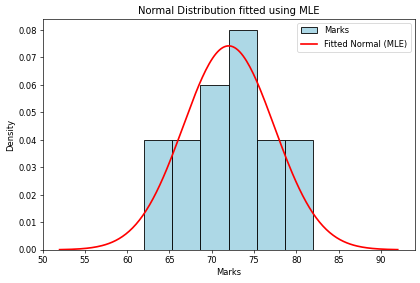

In [3]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

marks = pd.read_csv("marks_15.csv")["Marks"].values
n = len(marks)

mu_hat = np.sum(marks) / n
var_hat = np.sum((marks - mu_hat) ** 2) / n
std_hat = np.sqrt(var_hat)

print("Number of students       :", n)
print("MLE of mean (mu)         =", round(mu_hat, 4))
print("MLE of variance (sigma^2)=", round(var_hat, 4))
print("MLE of std deviation     =", round(std_hat, 4))

mu_s, sd_s = norm.fit(marks)
print("\nscipy norm.fit check     : mean =", round(mu_s, 4), " std =", round(sd_s, 4))

x = np.linspace(marks.min() - 10, marks.max() + 10, 200)
plt.figure(figsize=(8, 5))
plt.hist(marks, bins=6, density=True, color="lightblue", edgecolor="black", label="Marks")
plt.plot(x, norm.pdf(x, mu_hat, std_hat), color="red", linewidth=2, label="Fitted Normal (MLE)")
plt.title("Normal Distribution fitted using MLE")
plt.xlabel("Marks")
plt.ylabel("Density")
plt.legend()
plt.show()
